In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Wedge, Circle

In [ ]:
data = pd.read_csv('/content/cansat-test.csv')
print('CanSat Data: ')
print(data.head(4))

CanSat Data: 
   Time  Temperature  Humidity  Pressure  Altitude  Velocity
0   0.0        37.67     23.14    979.12      0.00       0.0
1   0.5        37.67     23.11    979.11     -0.01       0.0
2   1.0        37.67     23.08    979.11     -0.01       0.0
3   1.5        37.67     23.06    979.12     -0.01       0.0


In [ ]:
cansat_temp = data['Temperature'].mean()
cansat_humidity = data['Humidity'].mean()
cansat_pressure = data['Pressure'].mean()
print('CanSat Temperature: ', cansat_temp)
print('CanSat Humidity: ', cansat_humidity)
print('CanSat Pressure: ', cansat_pressure)

CanSat Temperature:  38.35351939451277
CanSat Humidity:  23.967426679280983
CanSat Pressure:  978.6346357615895


In [ ]:
sat_data = pd.read_csv('/content/satellite-data.csv', skiprows=14)
print('Satellite Data: \n')
print(sat_data.head(5))

Satellite Data: 

   YEAR  MO  DY  HR  ALLSKY_SFC_SW_DWN     PS  WS2M   RH2M    T2M  PRECTOTCORR
0  2026   3   7   0               -999  98.12  1.06  74.52  23.10            0
1  2026   3   7   1               -999  98.06  0.84  77.76  22.58            0
2  2026   3   7   2               -999  98.02  0.72  78.55  22.36            0
3  2026   3   7   3               -999  98.03  0.61  77.36  22.42            0
4  2026   3   7   4               -999  98.09  0.47  75.86  22.52            0


In [ ]:
sat_avg = sat_data[sat_data['HR'].isin([14,15])]
sat_avg

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,PS,WS2M,RH2M,T2M,PRECTOTCORR
14,2026,3,7,14,-999,97.94,1.28,30.77,35.11,0
15,2026,3,7,15,-999,97.91,1.28,31.69,34.62,0


# **Temperature:**

In [ ]:
# Konfigurasi
MIN_TEMP, MAX_TEMP = 0, 50
GAUGE_WIDTH = 0.25
TICK_STEP = 5

COLOR_ZONES = [
    (15, '#3b82f6'),
    (25, '#22c55e'),
    (35, '#f59e0b'),
    (np.inf, '#ef4444')
]

In [ ]:
def get_color(value):
  for limit, color in COLOR_ZONES:
    if value <= limit:
      return color

def draw_gauge(ax, value, label):
  normalized = np.clip(
      (
          value - MIN_TEMP
      ) / (MAX_TEMP - MIN_TEMP), 0, 1
  )

  # settings sudut dalam derajat: 180° (kiri) -> 0° (kanan)
  end_angle = 180 - 180 * normalized
  ax.add_patch(Wedge((0,0), 1, end_angle, 180, width=GAUGE_WIDTH, facecolor=get_color(value), edgecolor='white'))

  for t in np.arange(MIN_TEMP, MAX_TEMP + 1, TICK_STEP):
    theta = np.pi * (1 - (t - MIN_TEMP) / (MAX_TEMP - MIN_TEMP))
    ax.plot([0.97 * np.cos(theta), 1.05 * np.cos(theta)],
            [0.97 * np.sin(theta), 1.05 * np.sin(theta)],
            color='gray', linewidth=1.5)

    ax.text(1.15 * np.cos(theta), 1.15 * np.sin(theta), f'{t}°',
            ha='center', va='center', fontsize=9, color='dimgray')


  # jarum indikator
  needle_angle = np.pi * (1 - normalized)
  ax.plot(
      [
          0, 0.72 * np.cos(needle_angle)
      ],

      [
          0, 0.72 * np.sin(needle_angle)
      ],
      color='#111827', linewidth=2,
      solid_capstyle='round'
  )

  ax.add_patch(Circle((0,0), 0.06, color='#111827', zorder=5))

  ax.text(
      0, 0.35, f'{value:.3f} °C',
      ha='center', va='center',
      fontsize=18, fontweight='bold'
  )

  ax.text(
      0, -0.2, label, ha='center',
      va='center', fontsize=14, fontweight='bold',
      color='#374151'
  )

  ax.set_xlim(-1.3, 1.3)
  ax.set_ylim(-0.4, 1.3)
  ax.set_aspect('equal')
  ax.axis('off')

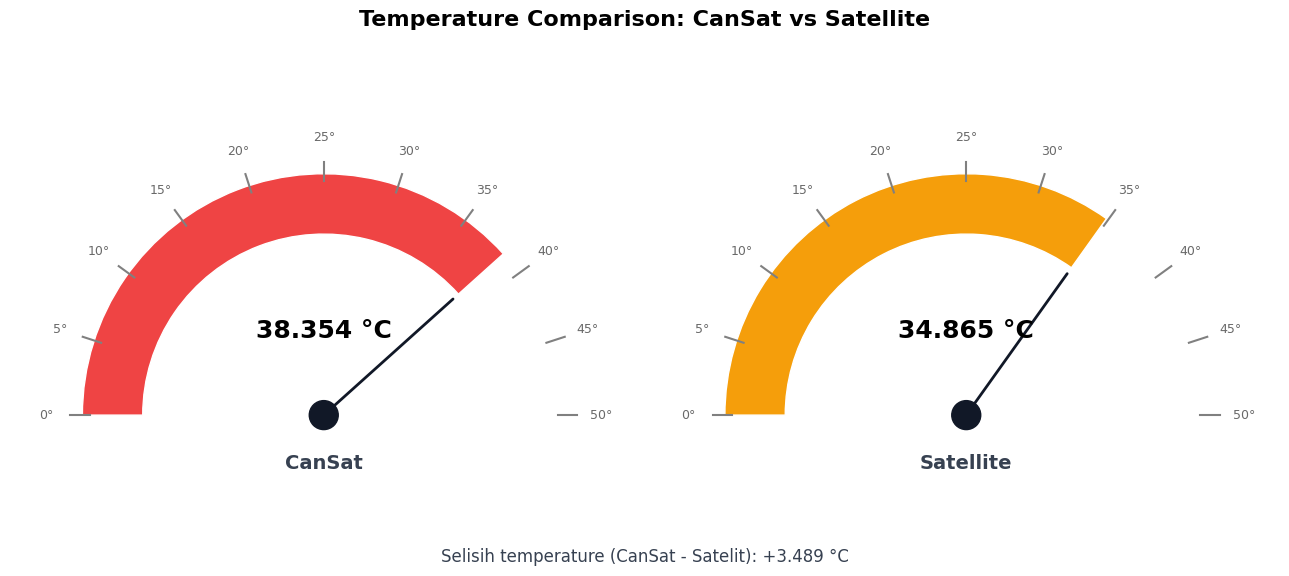

In [ ]:
cansat_temp = data['Temperature'].mean()
sat_temp = sat_avg['T2M'].mean()

if np.isnan(cansat_temp) or np.isnan(sat_temp):
  raise ValueError('Data Suhu Mengandung NaN. Periksa data CanSat/Satelit.')

values = [cansat_temp, sat_temp]
labels = ['CanSat', 'Satellite']

fig, axes = plt.subplots(1, 2, figsize=(13,6))
for ax, value, label in zip(axes, values, labels):
  draw_gauge(ax, value, label)


fig.suptitle(
    'Temperature Comparison: CanSat vs Satellite', fontsize=16, fontweight='bold'
)

diff = cansat_temp - sat_temp
fig.text(
    0.5, 0.06, f'Selisih temperature (CanSat - Satelit): {diff:+.3f} °C',
    ha='center', fontsize=12, color='#374151'
)
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

# **Humidity:**

In [ ]:
MIN_HUM, MAX_HUM = 0, 60
GAUGE_WIDTH = 0.25
TICK_STEP_HUM = 10

HUM_COLOR_ZONES = [
    (30, '#f59e0b'),
    (60, '#22c55e'),
    (80, '#3b82f6'),
    (np.inf, '#6366f1')
]

In [ ]:
def get_color_generic(value, zones):
  for limit, color in zones:
    if value <= limit:
      return color

def draw_gauge_generic(ax, value, label, min_val, max_val, tick_step, zones, unit):
  normalized = np.clip((value - min_val) / (max_val - min_val), 0, 1)

  # sudut dalam derajat: 180° (kiri) -> 0° (kanan)
  end_angle = 180 - 180 * normalized
  ax.add_patch(Wedge((0, 0), 1, end_angle, 180, width=GAUGE_WIDTH,
                     facecolor=get_color_generic(value, zones), edgecolor='white'))

  for t in np.arange(min_val, max_val + 1, tick_step):
    theta = np.pi * (1 - (t - min_val) / (max_val - min_val))
    ax.plot([0.97 * np.cos(theta), 1.05 * np.cos(theta)],
            [0.97 * np.sin(theta), 1.05 * np.sin(theta)],
            color='gray', linewidth=1.5)

    ax.text(1.15 * np.cos(theta), 1.15 * np.sin(theta), f'{t}',
            ha='center', va='center', fontsize=9, color='dimgray')

  # jarum indikator
  needle_angle = np.pi * (1 - normalized)
  ax.plot([0, 0.72 * np.cos(needle_angle)],
          [0, 0.72 * np.sin(needle_angle)],
          color='#111827', linewidth=2, solid_capstyle='round')

  ax.add_patch(Circle((0, 0), 0.06, color='#111827', zorder=5))

  ax.text(0, 0.35, f'{value:.3f} {unit}',
          ha='center', va='center', fontsize=18, fontweight='bold')

  ax.text(0, -0.2, label, ha='center', va='center',
          fontsize=14, fontweight='bold', color='#374151')

  ax.set_xlim(-1.3, 1.3)
  ax.set_ylim(-0.4, 1.3)
  ax.set_aspect('equal')
  ax.axis('off')

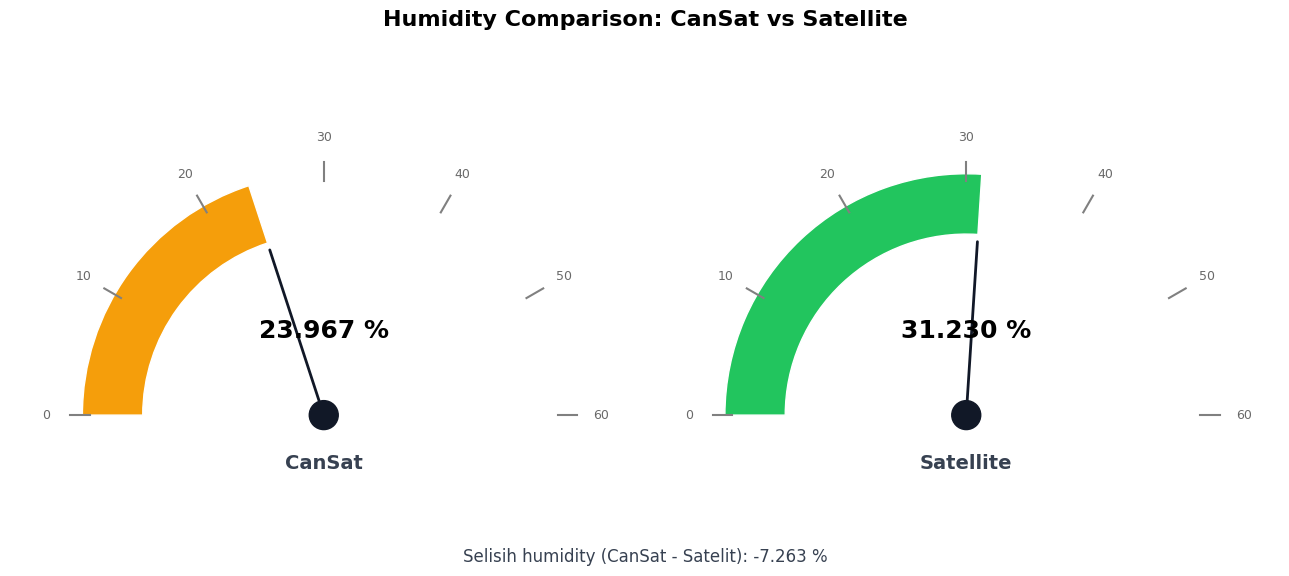

In [ ]:
cansat_humidity = data['Humidity'].mean()
sat_humidity = sat_avg['RH2M'].mean()

if np.isnan(cansat_humidity) or np.isnan(sat_humidity):
  raise ValueError('Data Kelembapan Mengandung NaN. Periksa data CanSat/Satelit.')

values = [cansat_humidity, sat_humidity]
labels = ['CanSat', 'Satellite']

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, value, label in zip(axes, values, labels):
  draw_gauge_generic(ax, value, label,
                     MIN_HUM, MAX_HUM, TICK_STEP_HUM,
                     HUM_COLOR_ZONES, '%')

fig.suptitle(
    'Humidity Comparison: CanSat vs Satellite', fontsize=16, fontweight='bold'
)

diff = cansat_humidity - sat_humidity
fig.text(
    0.5, 0.06, f'Selisih humidity (CanSat - Satelit): {diff:+.3f} %',
    ha='center', fontsize=12, color='#374151'
)
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

# **Pressure:**

In [ ]:
MIN_PRES, MAX_PRES = 900, 1010
GAUGE_WIDTH = 0.25
TICK_STEP_PRES = 10

PRES_COLOR_ZONES = [
    (960, '#f59e0b'),
    (1020, '#22c55e'),
    (1060, '#3b82f6'),
    (np.inf, '#6366f1')
]

In [ ]:
def get_color_generic(value, zones):
  for limit, color in zones:
    if value <= limit:
      return color

def draw_gauge_generic(ax, value, label, min_val, max_val, tick_step, zones, unit, color=None):
  normalized = np.clip((value - min_val) / (max_val - min_val), 0, 1)

  # warna tetap jika diberikan, jika tidak pakai warna zona
  gauge_color = color if color is not None else get_color_generic(value, zones)

  # sudut dalam derajat: 180° (kiri) -> 0° (kanan)
  end_angle = 180 - 180 * normalized
  ax.add_patch(Wedge((0, 0), 1, end_angle, 180, width=GAUGE_WIDTH,
                     facecolor=gauge_color, edgecolor='white'))

  for t in np.arange(min_val, max_val + 1, tick_step):
    theta = np.pi * (1 - (t - min_val) / (max_val - min_val))
    ax.plot([0.97 * np.cos(theta), 1.05 * np.cos(theta)],
            [0.97 * np.sin(theta), 1.05 * np.sin(theta)],
            color='gray', linewidth=1.5)

    ax.text(1.15 * np.cos(theta), 1.15 * np.sin(theta), f'{t}',
            ha='center', va='center', fontsize=9, color='dimgray')

  # jarum indikator
  needle_angle = np.pi * (1 - normalized)
  ax.plot([0, 0.72 * np.cos(needle_angle)],
          [0, 0.72 * np.sin(needle_angle)],
          color='#111827', linewidth=2, solid_capstyle='round')

  ax.add_patch(Circle((0, 0), 0.06, color='#111827', zorder=5))

  ax.text(0, 0.35, f'{value:.3f} {unit}',
          ha='center', va='center', fontsize=18, fontweight='bold')

  ax.text(0, -0.2, label, ha='center', va='center',
          fontsize=14, fontweight='bold', color='#374151')

  ax.set_xlim(-1.3, 1.3)
  ax.set_ylim(-0.4, 1.3)
  ax.set_aspect('equal')
  ax.axis('off')

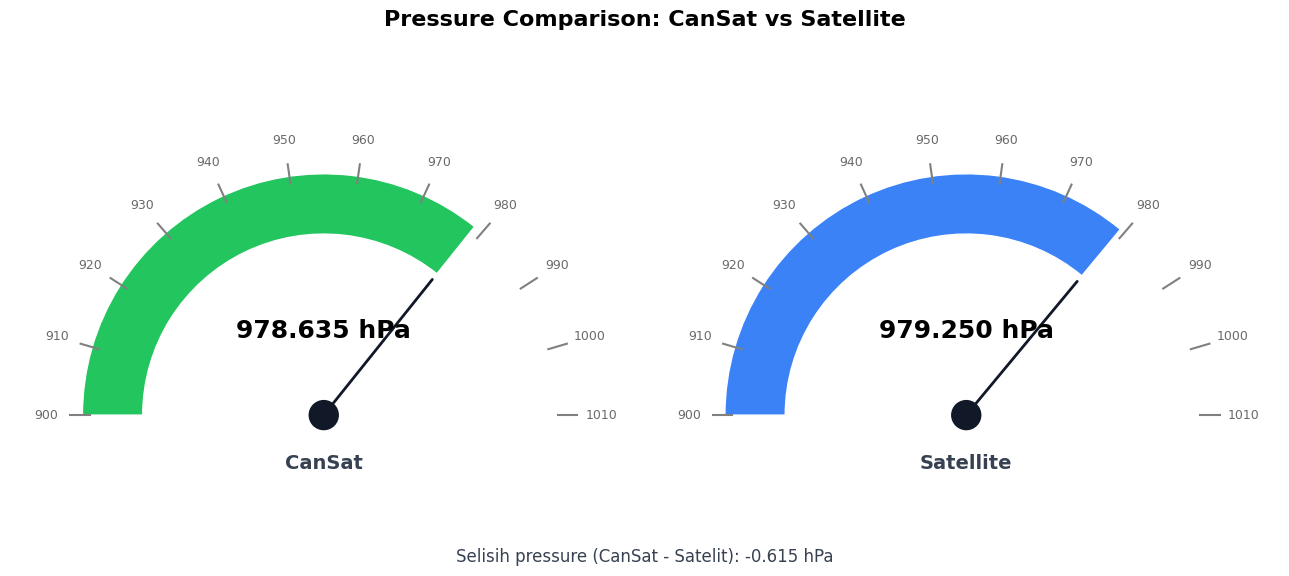

In [ ]:
cansat_pressure = data['Pressure'].mean()
sat_pressure = sat_avg['PS'].mean() * 10

if np.isnan(cansat_pressure) or np.isnan(sat_pressure):
  raise ValueError('Data Tekanan Mengandung NaN. Periksa data CanSat/Satelit.')

values = [cansat_pressure, sat_pressure]
labels = ['CanSat', 'Satellite']
source_colors = ['#22c55e', '#3b82f6']  # CanSat = hijau, Satellite = biru

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, value, label, col in zip(axes, values, labels, source_colors):
  draw_gauge_generic(ax, value, label,
                     MIN_PRES, MAX_PRES, TICK_STEP_PRES,
                     PRES_COLOR_ZONES, 'hPa', color=col)

fig.suptitle(
    'Pressure Comparison: CanSat vs Satellite', fontsize=16, fontweight='bold'
)

diff = cansat_pressure - sat_pressure
fig.text(
    0.5, 0.06, f'Selisih pressure (CanSat - Satelit): {diff:+.3f} hPa',
    ha='center', fontsize=12, color='#374151'
)
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()